<a href="https://colab.research.google.com/github/Swetha0407/Computer-vision/blob/main/Exp28.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install opencv-contrib-python==4.10.0.84

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.7/68.7 MB 16.9 MB/s  0:00:04
  Attempting uninstall: opencv-contrib-python
    Found existing installation: opencv-contrib-python 4.14.0.94
    Uninstalling opencv-contrib-python-4.14.0.94:
      Successfully uninstalled opencv-contrib-python-4.14.0.94


Saving eye_detection_input.jpg to eye_detection_input (2).jpg
Image uploaded successfully: eye_detection_input (2).jpg
Number of faces detected: 1
Number of eyes detected: 2


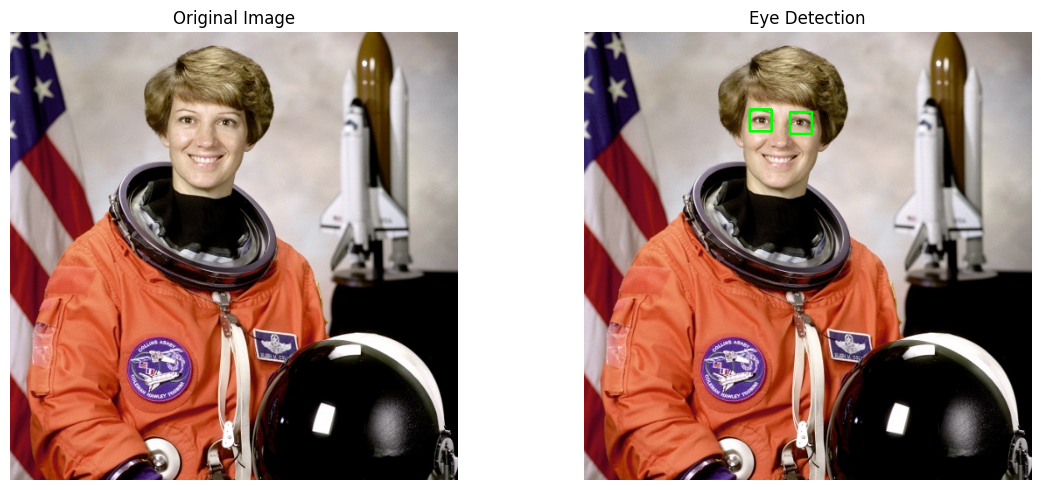

In [4]:
from google.colab import files
uploaded = files.upload()

import cv2
import matplotlib.pyplot as plt

# Read uploaded image
filename = list(uploaded.keys())[0]
image = cv2.imread(filename)

if image is None:
    raise ValueError("Could not read the uploaded image.")

print("Image uploaded successfully:", filename)

# Convert image to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Load face and eye detection classifiers
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

eye_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_eye.xml"
)

if face_cascade.empty() or eye_cascade.empty():
    raise RuntimeError("Could not load Haar Cascade classifiers.")

# Detect faces
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(80, 80)
)

# Create a copy of the original image
result = image.copy()
total_eyes = 0

# Detect eyes inside each face
for (x, y, w, h) in faces:

    # Extract upper face region
    face_gray = gray[y:y + int(h * 0.65), x:x + w]

    # Detect eyes
    eyes = eye_cascade.detectMultiScale(
        face_gray,
        scaleFactor=1.1,
        minNeighbors=7,
        minSize=(20, 20),
        maxSize=(int(w * 0.35), int(h * 0.35))
    )

    # Draw rectangles around detected eyes
    for (ex, ey, ew, eh) in eyes:
        cv2.rectangle(
            result,
            (x + ex, y + ey),
            (x + ex + ew, y + ey + eh),
            (0, 255, 0),
            2
        )

        total_eyes += 1

print("Number of faces detected:", len(faces))
print("Number of eyes detected:", total_eyes)

# Display original and eye-detected images
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Eye Detection")
plt.axis("off")

plt.tight_layout()
plt.show()